# 08 Hybrid search
So far I tested each part on its own: TF-IDF and sentence vectors on titles, CLIP on pictures, and the attributes. Here I mix all of them into one **hybrid search** and choose how much each part counts (its weight) from my ratings. Nothing here uses the 20 locked final products.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
plt.rcParams.update(
    {"figure.figsize": (7, 3.4), "axes.spines.top": False, "axes.spines.right": False}
)
BLUE, GREEN, ORANGE, GREY = "#4c78a8", "#54a24b", "#f58518", "#c7c7c7"
pd.set_option("display.width", 170)

results = root / "results"
first = json.loads((results / "hybrid_tuning_first_round.json").read_text(encoding="utf-8"))
final = json.loads((results / "hybrid_tuning.json").read_text(encoding="utf-8"))
coverage = json.loads((results / "dev_hybrid_search_coverage.json").read_text(encoding="utf-8"))
board = pd.read_csv(results / "dev_hybrid_scoreboard.csv").set_index("method")
pairs = pd.read_csv(results / "dev_hybrid_pairwise.csv")
print("loaded the saved results")

loaded the saved results


## 1. The parts
Each part gives a score from 0 to 1 for a pair of products. A weighted sum of the scores (a *weighted linear combination*) is the final score. If a product lacks a value, that part is skipped and the other weights are scaled up, so nothing is guessed.

In [2]:
parts = pd.DataFrame(
    [
        ("title", "TF-IDF similarity of the titles (matches words)"),
        (
            "text_vectors",
            "cosine similarity of the sentence-model vectors of the titles (matches meaning)",
        ),
        ("image", "cosine similarity of the CLIP picture vectors"),
        ("category", "same category = 1, otherwise 0"),
        ("brand", "same brand = 1, otherwise 0"),
        ("audience", "same audience (men, women, kids) = 1, otherwise 0"),
        ("price", "closeness on a log scale (10 times apart = 0)"),
        ("colour", "overlap of the colour lists (Jaccard)"),
        ("weight", "closeness on a log scale"),
        ("rating", "closeness (4 stars apart = 0)"),
    ],
    columns=["part", "how two products are compared"],
).set_index("part")
display(parts)

,how two products are compared
part,
title,TF-IDF similarity of the titles (matches words)
text_vectors,cosine similarity of the sentence-model vector...
image,cosine similarity of the CLIP picture vectors
category,"same category = 1, otherwise 0"
brand,"same brand = 1, otherwise 0"
audience,"same audience (men, women, kids) = 1, otherwise 0"
price,closeness on a log scale (10 times apart = 0)
colour,overlap of the colour lists (Jaccard)
weight,closeness on a log scale


### What this shows
Two parts are new here. The sentence-vector part and the picture part use cosine similarity, shifted so that 0 means "as similar as two random products" (about 0.32 for the sentence vectors and 0.67 for CLIP). Without the shift, every pair of clothes would look similar to CLIP and the picture part would hardly separate anything.

## 2. Choosing the weights
**Coordinate ascent** changes one weight at a time. It tries a list of values for that weight, keeps the one with the best nDCG@10 on my ratings, then moves on to the next weight. It goes around until a full round changes nothing. To avoid a poor result, I started it from five different starting points (the untuned weights, two mixed starts and two random ones) and kept the best. This is the method of Metzler and Croft (2007) for linear feature-based models.

**5-fold cross-validation** checks that the weights are not fitted to my 30 products by luck. I split the 30 products into 5 groups of 6, tuned on 24, and scored the 6 left out. Doing this five times gives every product a score from weights that had not seen it (an *out-of-fold* score).

I tried two mixes:
- **10 weights:** one weight for every part.
- **4 weights:** one for the TF-IDF title, one for the sentence title, one for the picture, and one for all the attributes together (they keep their untuned shares).

## 3. First try
My first ratings covered the results of the earlier methods. The tuned hybrid found results that none of them had returned, so they had no rating and counted as bad matches.

In [3]:
table = pd.DataFrame(
    {
        "on all 30 products": [
            first["untuned_ndcg_at_10"],
            first["tuned_ndcg_at_10"],
            first["four_weights"]["ndcg_at_10"],
        ],
        "on unseen products (cross-validation)": [
            first["cross_validation"]["mean_untuned_test"],
            first["cross_validation"]["mean_test"],
            first["four_weights"]["mean_test"],
        ],
    },
    index=["untuned weights", "tuned, 10 weights", "tuned, 4 weights"],
).round(3)
display(table)

,on all 30 products,on unseen products (cross-validation)
untuned weights,0.637,0.637
"tuned, 10 weights",0.668,0.614
"tuned, 4 weights",0.674,0.635


### What this shows
The tuned weights scored higher on the products they were tuned on, but not on unseen products. The 10-weight mix even fell below the untuned one (0.614 against 0.637). The problem was partly the missing ratings, which made the search favour results I had already rated.

## 4. Rating the new results
I collected the results of the untuned mix and of both tuned mixes that had no rating. I rated them myself on a blind page, shuffled for each product and without method names, using the same 0, 1, 2 rule as before. The 20 locked products were never returned.

In [4]:
print(
    f"new results to rate: {coverage['new_results_to_rate']} (for {coverage['products_with_new_results']} products)"
)
for name, c in coverage["coverage"].items():
    print(
        f"{name}: {c.get('unrated', 0)} of {coverage['results_per_mix']} results had no rating before"
    )

new results to rate: 107 (for 23 products)
untuned: 2 of 300 results had no rating before
tuned_10_weights: 64 of 300 results had no rating before
tuned_4_weights: 67 of 300 results had no rating before


## 5. Tuning again
With the new ratings, I ran coordinate ascent and the 5-fold cross-validation again.

In [5]:
cv = final["cross_validation"]
four = final["four_weights"]
table = pd.DataFrame(
    {
        "on all 30 products": [
            final["untuned_ndcg_at_10"],
            final["tuned_ndcg_at_10"],
            four["ndcg_at_10"],
        ],
        "on unseen products (cross-validation)": [
            cv["mean_untuned_test"],
            cv["mean_test"],
            four["mean_test"],
        ],
    },
    index=["untuned weights", "tuned, 10 weights", "tuned, 4 weights"],
).round(3)
display(table)

,on all 30 products,on unseen products (cross-validation)
untuned weights,0.637,0.637
"tuned, 10 weights",0.803,0.764
"tuned, 4 weights",0.808,0.806


### What this shows
Now tuning clearly helps on unseen products: 0.764 for 10 weights and 0.806 for 4 weights, against 0.637 untuned. For the 4-weight mix, the score on all 30 products (0.808) is almost the same as on unseen products (0.806), which is a good sign that it is not fitted by luck.

## 6. The final weights
The 4-weight mix, tuned on all 30 products, shown with the 10-weight mix for comparison.

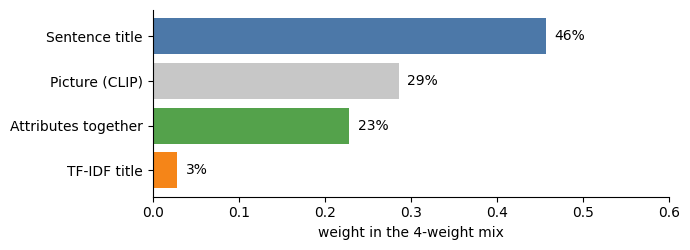

,title,text_vectors,image,category,brand,audience,price,colour,weight,rating
10-weight mix,0.062,0.375,0.312,0.062,0.031,0.031,0.031,0.016,0.047,0.031


In [6]:
four_weights = final["four_weights"]["weights"]
attribute_share = {
    "category": 0.20,
    "brand": 0.10,
    "audience": 0.10,
    "price": 0.10,
    "colour": 0.05,
    "weight": 0.05,
    "rating": 0.05,
}
fig, ax = plt.subplots(figsize=(7, 2.6))
names = ["text_vectors", "image", "attributes", "title"]
labels = ["Sentence title", "Picture (CLIP)", "Attributes together", "TF-IDF title"]
values = [four_weights[n] for n in names]
ax.barh(labels[::-1], values[::-1], color=[BLUE, GREY, GREEN, ORANGE][::-1])
for i, v in enumerate(values[::-1]):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center")
ax.set_xlim(0, 0.6)
ax.set_xlabel("weight in the 4-weight mix")
plt.tight_layout()
plt.show()
table = pd.DataFrame({"10-weight mix": final["tuned_weights"]}).round(3)
display(table.T)

### What this shows
The sentence vectors (46%) and the picture (29%) carry most of the weight. The TF-IDF title gets only 3%, because the sentence vectors already cover the title better. The attributes together get 23%.

## 7. Which parts matter
To find out how much each part matters, I removed one part at a time from the 10-weight mix (an *ablation*) and measured how much nDCG@10 drops.

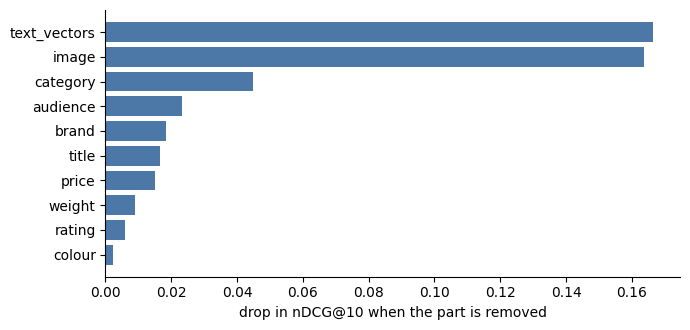

In [7]:
drops = pd.DataFrame(final["importance"]).set_index("part")["drop"].sort_values()
fig, ax = plt.subplots()
ax.barh(drops.index, drops.values, color=BLUE)
ax.set_xlabel("drop in nDCG@10 when the part is removed")
plt.tight_layout()
plt.show()

### What this shows
Removing the sentence vectors or the picture costs the most (about 0.165 each). Among the attributes, category matters most, and colour and rating barely matter. A part that costs almost nothing could be given a smaller weight.

## 8. Scoreboard
All methods are scored with the same ratings, and each shows one copy of each item. The hybrid scores are out-of-fold, so they come from products the weights had not seen. **nDCG@10** gives more credit to good results near the top. **Precision@10** is the share of the top 10 that I rated 1 or 2.

In [8]:
labels = {
    "hybrid_4_weights": "Hybrid, 4 weights",
    "hybrid_10_weights": "Hybrid, 10 weights",
    "image_clip_all": "CLIP (pictures)",
    "text_vectors": "Sentence vectors (titles)",
    "baseline": "Title (TF-IDF) and attributes (my baseline)",
    "title_only": "TF-IDF, title only",
    "attributes_only": "Attributes only",
}
table = pd.DataFrame(
    {
        "Method": list(labels.values()),
        "nDCG@10": [round(board.loc[m, "ndcg_at_10"], 3) for m in labels],
        "Precision@10": [round(board.loc[m, "precision_at_10"], 2) for m in labels],
    }
).set_index("Method")
display(table)

,nDCG@10,Precision@10
Method,,
"Hybrid, 4 weights",0.806,0.87
"Hybrid, 10 weights",0.764,0.82
CLIP (pictures),0.750,0.85
Sentence vectors (titles),0.659,0.76
Title (TF-IDF) and attributes (my baseline),0.637,0.74
"TF-IDF, title only",0.498,0.55
Attributes only,0.420,0.62


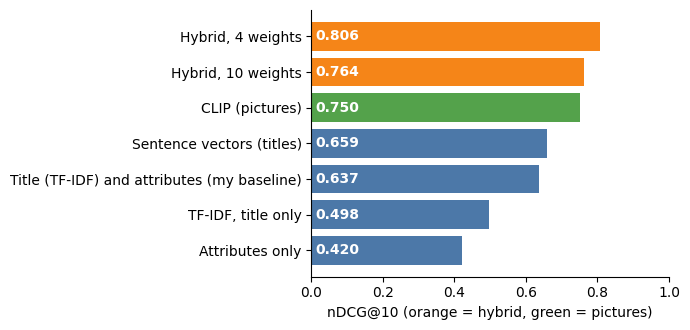

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.4))
names = list(labels)[::-1]
values = [board.loc[m, "ndcg_at_10"] for m in names]
colours = [
    ORANGE if m.startswith("hybrid") else GREEN if m == "image_clip_all" else BLUE for m in names
]
ax.barh([labels[m] for m in names], values, color=colours)
for i, v in enumerate(values):
    ax.text(0.01, i, f"{v:.3f}", va="center", color="white", fontweight="bold")
ax.set_xlim(0, 1)
ax.set_xlabel("nDCG@10 (orange = hybrid, green = pictures)")
plt.tight_layout()
plt.show()

### What this shows
The 4-weight hybrid has the highest score, then the 10-weight hybrid and CLIP. The baseline and the single text methods are lower.

## 9. Real or luck?
For each pair of methods, I compared the nDCG@10 on the same products. If the difference could come from the choice of products, I call it luck.

In [10]:
wanted = [
    ("hybrid_4_weights", "baseline"),
    ("hybrid_4_weights", "text_vectors"),
    ("hybrid_4_weights", "image_clip_all"),
    ("hybrid_4_weights", "hybrid_10_weights"),
]
rows = []
for a, b in wanted:
    hit = pairs[
        ((pairs["first"] == a) & (pairs["second"] == b))
        | ((pairs["first"] == b) & (pairs["second"] == a))
    ].iloc[0]
    sign = 1 if hit["first"] == a else -1
    rows.append(
        {
            "comparison": f"{labels[a]} minus {labels[b]}",
            "difference": f"{sign * hit['ndcg_difference']:+.3f}",
            "verdict": "real" if hit["difference_is_real"] else "could be luck",
        }
    )
display(pd.DataFrame(rows).set_index("comparison"))

,difference,verdict
comparison,,
"Hybrid, 4 weights minus Title (TF-IDF) and attributes (my baseline)",+0.168,real
"Hybrid, 4 weights minus Sentence vectors (titles)",+0.146,real
"Hybrid, 4 weights minus CLIP (pictures)",+0.055,could be luck
"Hybrid, 4 weights minus Hybrid, 10 weights",+0.042,real


### What this shows
The 4-weight hybrid is clearly better than the baseline, the sentence vectors, and the 10-weight hybrid. Against CLIP alone, the gap could be luck with 30 products, so I do not call a winner there.

## 10. Recorded in MLflow
Every run is saved in MLflow with its settings and scores. First, the check for luck from the first try, and then all seven methods side by side:

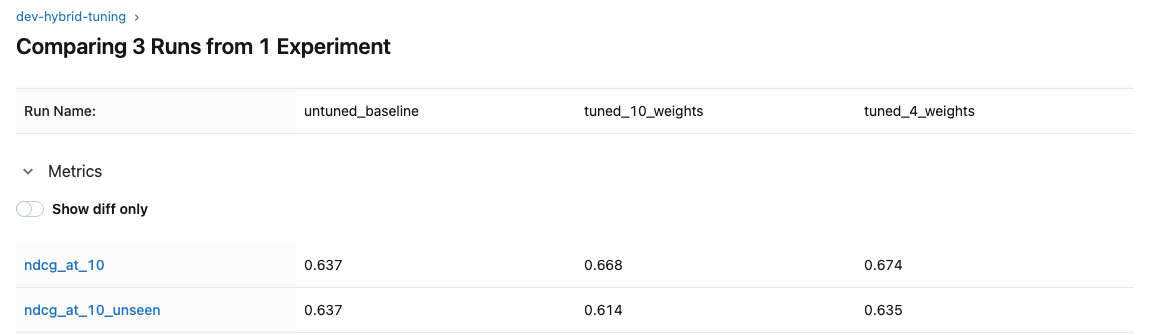

In [11]:
from IPython.display import Image

Image(filename=root / "evaluation" / "mlflow_hybrid_tuning_runs.png", width=900)

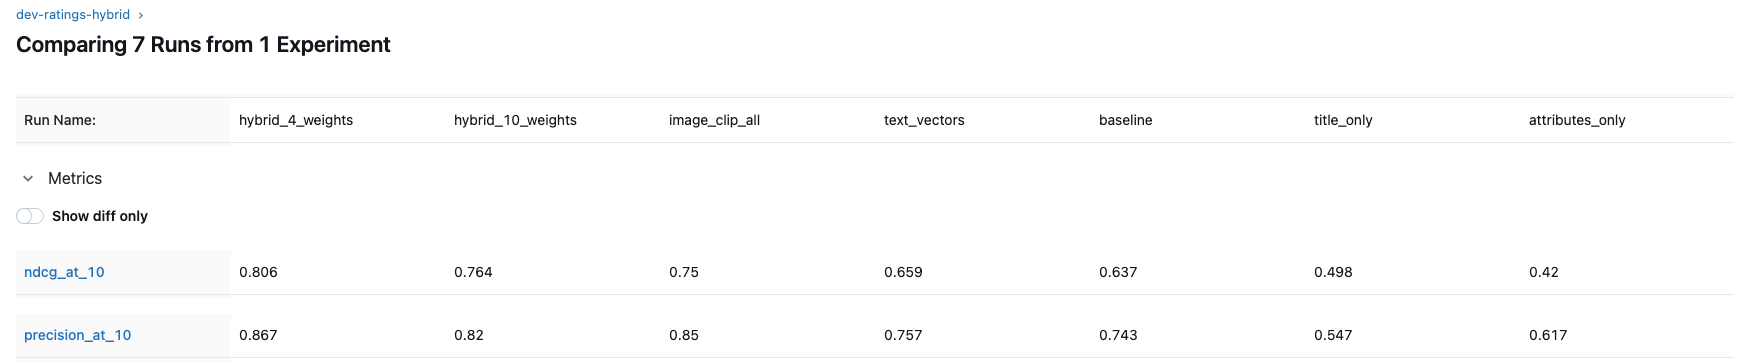

In [12]:
Image(filename=root / "evaluation" / "mlflow_hybrid_runs.png", width=1000)

## 11. Conclusion

**What I wanted to know:** if I mix all the parts into one search, is it better than each part on its own?

**What I did.** I took ten parts: the TF-IDF title, the sentence title, the CLIP picture, category, brand, audience, price, colour, weight and rating. Each part scores a pair of products. I added the scores with weights (a weighted linear combination), and a weight says how much a part counts.

To choose the weights, I used **coordinate ascent**. I change one weight at a time, keep the change if nDCG@10 goes up, and repeat until nothing improves. I started from several starting points and kept the best.

To make sure the weights are not just lucky for my 30 products, I used **5-fold cross-validation**. I tuned the weights on 24 products and tested them on the 6 I had left out, five times. All the hybrid scores below come from products the weights had not seen.

I tried two mixes: one with 10 weights, and one with only 4 weights (TF-IDF title, sentence title, picture, and all attributes together).

My first try did not beat my baseline, because the hybrid found 107 new results that were not in my ratings yet. I rated those myself, without knowing which mix found them, and tuned again. I used one set of my ratings to check every method, so the comparison is fair, and I show only one copy of each item.

| Method | nDCG@10 | Precision@10 |
|---|---|---|
| Hybrid, 4 weights | 0.806 | 0.87 |
| Hybrid, 10 weights | 0.764 | 0.82 |
| CLIP (pictures) | 0.750 | 0.85 |
| Sentence vectors (titles) | 0.659 | 0.76 |
| Title (TF-IDF) and attributes (my baseline) | 0.637 | 0.74 |
| TF-IDF, title only | 0.498 | 0.55 |
| Attributes only | 0.420 | 0.62 |

Precision@10 is how many of the top 10 I rated 1 or 2.

**What I found**

- The 4-weight hybrid is clearly better than my baseline, the sentence vectors, TF-IDF and the attributes alone.
- It is ahead of CLIP, but with only 30 products I can't be sure it is really better.
- The mix with 4 weights did better than the one with 10, because fewer weights means less chance of fitting my 30 products by luck.
- Sentence vectors and pictures matter most. If I remove either one, the score drops by about 0.165. Category is the most useful attribute.

**What I can't say yet**

- I tested only 30 products, and I was the only person rating.
- I tuned the weights on these 30 products, so I will test them once on my 20 final products at the end.

**What I do next.** I will make the search fast with an index (FAISS, HNSW, Annoy) and test making the vectors smaller with PCA.